# Experiments: first iteration

Milestone 4 of *Evaluating lineage link prediction with Valentine*.

This notebook runs Valentine on all 842 candidate table pairs built in `03_preprocessing.ipynb`, turns column
scores into table-pair scores, evaluates them as a lineage-link ranking and compares them with baselines and with
the GNN results of the reference paper (Dutkiewicz et al., RDDL ontology).

| step | question | code | section |
|---|---|---|---|
| 1. Run the matchers | 6 Valentine configurations × 842 ordered pairs | `src/matching.py` | 1 |
| 2. Column → table scores | which aggregation of column scores identifies a link best? | `src/evaluation.py` | 2 |
| 3. Evaluate as a ranking | PR-AUC, AUROC (all pairs), Hits@k, MRR (per derived table) | `src/evaluation.py` | 3 |
| 4. Evaluate as a classifier | Precision / Recall / F1 at a threshold chosen on `train` only | `src/evaluation.py` | 4 |
| 5. Baselines | does Valentine beat random ranking, table names, raw value overlap? | `src/evaluation.py` | 5 |
| 6. Error analysis | what are the false positives, which links are missed, is the direction right? | - | 6 |
| 7. Reference paper | what can and cannot be compared with the GNN results | - | 7 |

**Evaluation protocol.** Valentine is not trained, so the only choices fitted to data are *which matcher /
aggregation* and *which threshold*. Both are chosen on `train`; `test` and `multi` (19 of the 30 links) are reported
as **held-out**. Results on all three splits together are given as well.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..", "src").resolve()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_curve

from evaluation import (AGGREGATIONS, best_threshold, containment_baseline, direction_check, evaluate_all,
                        hits_and_rr, hits_vs_sampled_negatives, name_baseline, random_baseline,
                        ranking_metrics, table_scores, threshold_metrics, threshold_table)
from matching import FAMILY, MATCHERS, RESULTS_DIR, SOLVER, column_scores
from preprocessing import load_processed

pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)
FIGURES = Path("..", "docs", "figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Same chart style as the EDA and pre-processing notebooks.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, LIGHT_GREY, MUTED, GRID, SURFACE = "#898781", "#c3c2b7", "#52514e", "#e1e0d9", "#ffffff"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 8,
    "axes.edgecolor": LIGHT_GREY, "axes.labelcolor": MUTED, "axes.titlesize": 8.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

HELD_OUT = ["test", "multi"]
METRICS = ["PR-AUC", "AUROC", "Hits@1", "Hits@3", "Hits@10", "MRR"]

data, pairs, tables = load_processed()
print(len(pairs), "candidate pairs,", int(pairs.is_lineage.sum()), "lineage links")
pairs.groupby("split").agg(pairs=("label", "size"), links=("is_lineage", "sum")).reindex(["train", "test", "multi"])

842 candidate pairs, 30 lineage links


,pairs,links
split,,
train,420,11
test,182,5
multi,240,14


## 1. Running the matchers

Every ordered pair `source -> target` is passed to Valentine as `[source, target]` with the raw table names and
all rows (`instance_sample_size=None`). The six configurations are the five matchers of Valentine, with COMA run
twice: on the schema only and with instances. Results are cached in `results/column_scores_raw.csv.gz`; delete
that file (or call `column_scores(overwrite=True)`) to recompute.

> **Compatibility note.** `DistributionBased` solves a small integer program with the CBC solver. With PuLP 4.x the
> bundled CBC crashes on some problems, and Valentine passes an invalid (negative) random seed. `src/matching.py`
> patches this: valid seed, CBC pre-processing off, and HiGHS (`pip install highspy`) as a fallback solver for the
> pairs where CBC still fails. All of these are exact solvers, so the matches do not change.

In [2]:
scores, timings = column_scores("raw")
runtime = timings.groupby("matcher").seconds.agg(total="sum", mean="mean", slowest="max")
runtime.insert(0, "uses", runtime.index.map(FAMILY))
runtime["pairs with >= 1 match"] = scores.groupby("matcher").apply(
    lambda g: len(g[["split", "source", "target"]].drop_duplicates()))
runtime.reindex(list(MATCHERS)).round(3)

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
  Distribution-based: 100/842 pairs
  Distribution-based: 200/842 pairs
  Distribution-based: 300/842 pairs
  Distribution-based: 400/842 pairs
  Distribution-based: 500/842 pairs
  Distribution-based: 600/842 pairs
  Distribution-based: 700/842 pairs
  Distribution-based: 800/842 pairs
Distribution-based: 842 pairs in 59 s


,uses,total,mean,slowest,pairs with >= 1 match
matcher,,,,,
COMA (schema),schema,1.857,0.002,0.024,842
COMA (schema + instances),schema + instances,12.241,0.015,0.097,842
Cupid,schema,6.022,0.007,1.033,638
Similarity Flooding,schema,20.264,0.024,0.186,842
Jaccard distance,instances,7.979,0.009,0.108,686
Distribution-based,instances,58.801,0.070,0.408,462


All six configurations together take **less than 4 minutes** for the 842 pairs on a single CPU core, with no
training. COMA and Similarity Flooding return at least one column pair for every table pair, because some names
are always somewhat similar. The instance-based matchers return nothing for pairs without shared values
(Distribution-based keeps only 462 of the 842 pairs), so they already discard many unrelated candidates.

## 2. From column scores to table-pair scores

For a pair `source -> target`, each **target** column gets the best score of any source column (0 if Valentine
returned none). These per-column scores are aggregated into one score:

In [3]:
pd.Series(AGGREGATIONS, name="aggregation").to_frame()

,aggregation
max,best single target column (catches a source that gave on...
top3,mean of the three best target columns
mean,mean over all target columns (rewards full copies)
coverage,share of target columns with score >= 0.5


In [4]:
scored = table_scores(scores, pairs, data)
scored.to_csv(RESULTS_DIR / "table_scores_raw.csv", index=False)
example = scored[(scored.split == "train") & (scored.target == "vworderfulfillment")
                 & (scored.matcher == "Jaccard distance")]
(example.pivot_table(index=["source_name", "label"], columns="aggregation", values="score")
 .sort_values("mean", ascending=False).head(6).round(2))

,aggregation,coverage,max,mean,top3
source_name,label,,,,
Orders,lineage,0.8,1.00,0.80,1.00
vwOrderEmployeeContext,sibling,0.6,1.00,0.60,1.00
TableFulfillmentLeads,reverse,0.2,1.00,0.42,0.59
Shippers,lineage,0.2,1.00,0.20,0.33
OrderDetails,unrelated,0.2,1.00,0.20,0.33
Customers,lineage,0.2,0.98,0.20,0.33


`mean` ranks the main source `Orders` first (0.80), but a *sibling* view (0.60) and the table derived from this
view (*reverse*, 0.42) come before the two other true sources, `Customers` and `Shippers`, which gave only one
column each to the join (0.20). `max` gives about 1.0 to all of them, and also to the unrelated `OrderDetails`
(shared `OrderID`), so it cannot separate them.

## 3. Ranking metrics

* **PR-AUC** (average precision) and **AUROC** over all candidate pairs of a split: can the score separate links
  from non-links? With only 3.6 % positives, PR-AUC is the informative one; a random ranking gets about the share of
  positives (0.06 on the held-out splits, section 5).
* **Hits@k, MRR**: for every derived table with a logged source, all other tables of the split (13 to 20) are
  ranked as candidate sources; Hits@k = a true source is in the first k, MRR = mean of 1 / rank of the first true
  source. Ties are counted against the matcher.

In [5]:
ranking = evaluate_all(scored)
ranking.to_csv(RESULTS_DIR / "metrics_ranking.csv", index=False)
held = ranking[ranking["evaluated on"] == "held-out (test+multi)"].set_index(["matcher", "aggregation"])
held[METRICS].sort_values("PR-AUC", ascending=False).round(3).head(10)

PR-AUC  AUROC  Hits@1  Hits@3  Hits@10    MRR
matcher                   aggregation                                               
Jaccard distance          mean          0.206  0.860   0.400   0.733    1.000  0.589
COMA (schema + instances) mean          0.201  0.845   0.333   0.600    1.000  0.552
Jaccard distance          coverage      0.187  0.829   0.267   0.533    0.867  0.472
Distribution-based        mean          0.186  0.793   0.333   0.533    0.933  0.519
COMA (schema + instances) top3          0.185  0.824   0.333   0.600    1.000  0.552
                          coverage      0.183  0.800   0.200   0.467    0.867  0.427
Distribution-based        coverage      0.177  0.790   0.200   0.467    0.800  0.406
COMA (schema)             mean          0.175  0.784   0.200   0.467    1.000  0.448
Cupid                     mean          0.173  0.836   0.267   0.667    0.933  0.483
Jaccard distance          top3          0.162  0.842   0.333   0.600    1.000  0.511

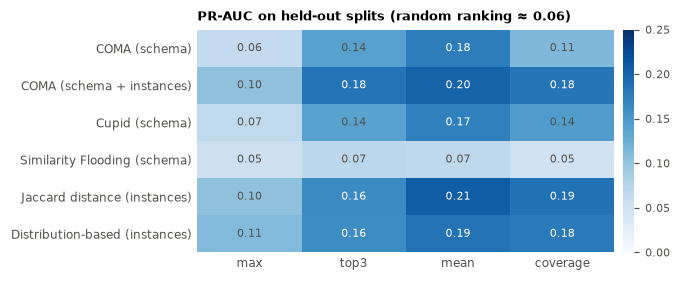

In [6]:
grid = held["PR-AUC"].unstack().reindex(index=list(MATCHERS), columns=list(AGGREGATIONS))
fig, ax = plt.subplots(figsize=(6.2, 2.6))
image = ax.imshow(grid.values, cmap="Blues", vmin=0, vmax=0.25, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), [m if "(" in m else f"{m} ({FAMILY[m]})" for m in grid.index])
ax.tick_params(length=0)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color=SURFACE if v > 0.15 else MUTED)
cbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=7, colors=MUTED)
ax.set_title("PR-AUC on held-out splits (random ranking ≈ 0.06)")
fig.tight_layout()
fig.savefig(FIGURES / "exp_01_prauc_grid.png")
plt.show()

* **Values beat names.** The best configurations use instances (Jaccard, COMA with instances, Distribution-based).
  The best schema-only matcher (COMA, `mean`) reaches 0.18, Similarity Flooding is close to random. This confirms
  the EDA expectation (shared values separate links far better than column names).
* **`mean` is the best aggregation for every matcher.** A derived table usually takes most of its columns from its
  source, and `mean` rewards that; `max` is fooled by single shared key columns.
* Selecting the configuration on `train` (highest PR-AUC there) picks **Jaccard distance + mean**, which is also
  the best configuration on the held-out splits, so the choice transfers.

In [7]:
train_rank = ranking[ranking["evaluated on"] == "train"].set_index(["matcher", "aggregation"])["PR-AUC"]
chosen = train_rank.idxmax()
print("configuration chosen on train:", chosen)
best = scored[(scored.matcher == chosen[0]) & (scored.aggregation == chosen[1])].copy()
ranking[(ranking.matcher == chosen[0]) & (ranking.aggregation == chosen[1])].set_index("evaluated on")[
    ["positives", "pairs"] + METRICS].round(3)

configuration chosen on train: ('Jaccard distance', 'mean')


,positives,pairs,PR-AUC,AUROC,Hits@1,Hits@3,Hits@10,MRR
evaluated on,,,,,,,,
train,11,420,0.405,0.885,0.750,0.875,1.0,0.833
test,5,182,0.154,0.845,0.667,1.000,1.0,0.778
multi,14,240,0.227,0.855,0.333,0.667,1.0,0.542
held-out (test+multi),19,422,0.206,0.860,0.400,0.733,1.0,0.589
all,30,842,0.213,0.875,0.522,0.783,1.0,0.674


## 4. Precision and recall at a threshold

A threshold is needed to output a set of links. It is chosen on `train` (maximum F1) and applied unchanged to
`test` and `multi`.

In [8]:
thresholds = threshold_table(scored)
thresholds.to_csv(RESULTS_DIR / "metrics_threshold.csv", index=False)
(thresholds[thresholds["evaluated on"] == "held-out (test+multi)"].drop(columns="evaluated on")
 .set_index(["matcher", "aggregation"]).sort_values("F1", ascending=False).round(3).head(8))

,,threshold,predicted links,Precision,Recall,F1
matcher,aggregation,,,,,
Jaccard distance,coverage,0.667,39,0.256,0.526,0.345
Distribution-based,mean,0.667,42,0.238,0.526,0.328
COMA (schema + instances),mean,0.568,49,0.224,0.579,0.324
COMA (schema),mean,0.900,27,0.259,0.368,0.304
Distribution-based,coverage,0.667,47,0.213,0.526,0.303
Cupid,mean,0.820,28,0.250,0.368,0.298
Jaccard distance,mean,0.796,22,0.273,0.316,0.293
Distribution-based,top3,1.000,29,0.241,0.368,0.292


In [9]:
t_best = best_threshold(best[best.split == "train"])
pd.DataFrame({view: threshold_metrics(best[best.split.isin(members)], t_best)
              for view, members in [("train", ["train"]), ("held-out", HELD_OUT)]}).T.round(3)

,threshold,predicted links,Precision,Recall,F1
train,0.796,3.0,1.000,0.273,0.429
held-out,0.796,22.0,0.273,0.316,0.293


At its train threshold, Jaccard + `mean` finds about a third of the held-out links with a precision of about 0.3.
Section 6 shows that this precision is misleadingly low: **every** false positive is a pair inside a true lineage
chain.

## 5. Baselines without Valentine

| baseline | idea |
|---|---|
| random | random scores (mean of 500 runs) |
| table names | string similarity of the table names without type prefix, i.e. a guess from names alone |
| value containment | the EDA value score: share of each target column's distinct values found in one source column, averaged; a hand-written value matcher without Valentine |

In [10]:
baselines = {
    "random": None,
    "table names": name_baseline(pairs, tables),
    "value containment": containment_baseline(pairs, data),
}
rows = []
runs = random_baseline(pairs, repeats=500)
rows.append({"method": "random", "kind": "baseline",
             **pd.DataFrame([ranking_metrics(r[r.split.isin(HELD_OUT)]) for r in runs]).mean()})
for name in ["table names", "value containment"]:
    b = baselines[name]
    rows.append({"method": name, "kind": "baseline", **ranking_metrics(b[b.split.isin(HELD_OUT)])})
best_per_matcher = held.reset_index().sort_values("PR-AUC", ascending=False).groupby("matcher").head(1)
for r in best_per_matcher.itertuples():
    part = scored[(scored.matcher == r.matcher) & (scored.aggregation == r.aggregation) & scored.split.isin(HELD_OUT)]
    rows.append({"method": f"{r.matcher} + {r.aggregation}", "kind": f"Valentine ({FAMILY[r.matcher]})",
                 **ranking_metrics(part)})
comparison = pd.DataFrame(rows).set_index("method")
comparison.to_csv(RESULTS_DIR / "metrics_baselines.csv")
comparison.round(3)

,kind,PR-AUC,AUROC,Hits@1,Hits@3,Hits@10,MRR
method,,,,,,,
random,baseline,0.059,0.504,0.089,0.257,0.730,0.256
table names,baseline,0.125,0.638,0.400,0.533,0.867,0.523
value containment,baseline,0.221,0.861,0.333,0.733,1.000,0.544
Jaccard distance + mean,Valentine (instances),0.206,0.860,0.400,0.733,1.000,0.589
COMA (schema + instances) + mean,Valentine (schema + instances),0.201,0.845,0.333,0.600,1.000,0.552
Distribution-based + mean,Valentine (instances),0.186,0.793,0.333,0.533,0.933,0.519
COMA (schema) + mean,Valentine (schema),0.175,0.784,0.200,0.467,1.000,0.448
Cupid + mean,Valentine (schema),0.173,0.836,0.267,0.667,0.933,0.483
Similarity Flooding + top3,Valentine (schema),0.070,0.635,0.133,0.467,0.867,0.360


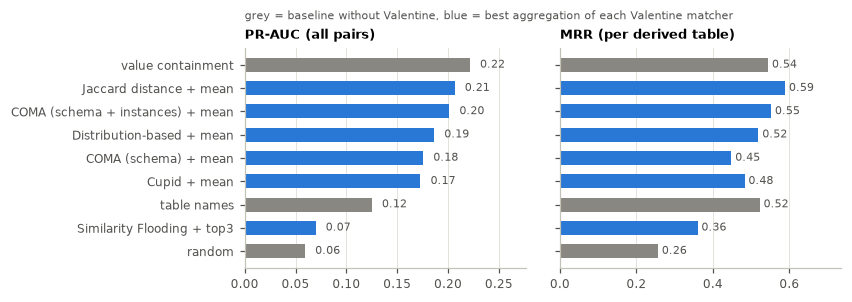

In [11]:
order = comparison.sort_values("PR-AUC").index
colors = [GREY if comparison.loc[m, "kind"] == "baseline" else BLUE for m in order]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6), sharey=True, gridspec_kw={"wspace": 0.12})
for ax, metric in zip(axes, ["PR-AUC", "MRR"]):
    values = comparison.loc[order, metric]
    ax.barh(range(len(order)), values, color=colors, height=0.6)
    for y, v in enumerate(values):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=7, color=MUTED)
    ax.set_yticks(range(len(order)), order)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, values.max() * 1.25)
    ax.set_title(metric + (" (all pairs)" if metric == "PR-AUC" else " (per derived table)"))
axes[0].text(0, 1.13, "grey = baseline without Valentine, blue = best aggregation of each Valentine matcher",
             transform=axes[0].transAxes, fontsize=7, color=MUTED)
fig.savefig(FIGURES / "exp_02_baselines.png")
plt.show()

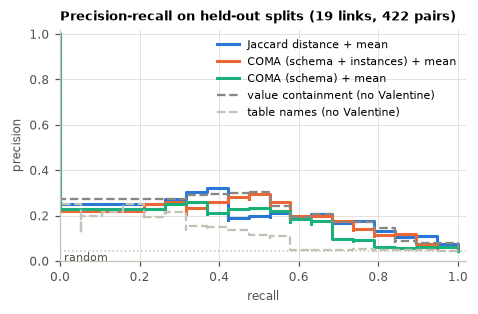

In [12]:
curves = [
    ("Jaccard distance + mean", best, BLUE, "-"),
    ("COMA (schema + instances) + mean",
     scored[(scored.matcher == "COMA (schema + instances)") & (scored.aggregation == "mean")], ORANGE, "-"),
    ("COMA (schema) + mean", scored[(scored.matcher == "COMA (schema)") & (scored.aggregation == "mean")], AQUA, "-"),
    ("value containment (no Valentine)", baselines["value containment"], GREY, "--"),
    ("table names (no Valentine)", baselines["table names"], LIGHT_GREY, "--"),
]
fig, ax = plt.subplots(figsize=(4.4, 2.9))
for label, df, color, style in curves:
    part = df[df.split.isin(HELD_OUT)]
    p, r, _ = precision_recall_curve(part.is_lineage, part.score)
    ax.plot(r, p, color=color, linestyle=style, linewidth=2 if style == "-" else 1.5, label=label,
            drawstyle="steps-post")
share = best[best.split.isin(HELD_OUT)].is_lineage.mean()
ax.axhline(share, color=LIGHT_GREY, linewidth=1, linestyle=":")
ax.text(0.01, share - 0.045, "random", ha="left", fontsize=7, color=MUTED)
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend(loc="upper right", fontsize=7)
ax.set_title("Precision-recall on held-out splits (19 links, 422 pairs)")
fig.tight_layout()
fig.savefig(FIGURES / "exp_03_pr_curves.png")
plt.show()

* Valentine's value-based matchers are **about 3.5× better than random** in PR-AUC (0.21 vs 0.06) and clearly
  better than a guess from table names (0.12).
* The hand-written **value containment** baseline is about as good as the best Valentine matcher (PR-AUC 0.22 vs
  0.21, MRR 0.54 vs 0.59). Valentine's Jaccard matcher computes essentially the same signal, so on this benchmark
  the benefit of Valentine is that it provides this signal, and the schema signal, *off the shelf*, not a better
  signal. This is an honest first-iteration finding that we will test further in Milestone 5 (combining matchers).
* Precision stays at 1.0 only for the first links; the curves drop early because of the hard negatives analysed
  next.

## 6. Error analysis

### 6.1 What are the top-ranked non-links?

In [13]:
from eda import PAIR_LABELS

label_colors = {"lineage": BLUE, "reverse": "#9fc3ee", "indirect": GREY, "sibling": "#a8a79f",
                "unlogged": LIGHT_GREY, "unrelated": "#e9e8e3"}
ranked = best.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
cutoffs = [10, 20, 30, 50, 100]
composition = pd.DataFrame({k: ranked.head(k).label.value_counts() for k in cutoffs}).T.reindex(
    columns=PAIR_LABELS).fillna(0).astype(int)
composition.index = [f"top {k}" for k in cutoffs]
composition

label,lineage,reverse,indirect,sibling,unlogged,unrelated
top 10,2,2,6,0,0,0
top 20,5,6,9,0,0,0
top 30,11,7,10,0,1,1
top 50,11,7,10,4,1,17
top 100,20,10,13,6,3,48


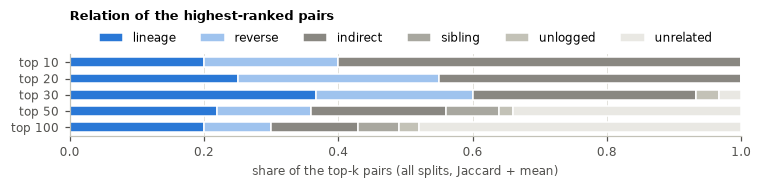

In [14]:
fig, ax = plt.subplots(figsize=(7.0, 1.9))
share = composition.div(composition.sum(axis=1), axis=0)
left = np.zeros(len(share))
for label in PAIR_LABELS:
    ax.barh(share.index, share[label], left=left, color=label_colors[label], height=0.6,
            edgecolor=SURFACE, linewidth=1, label=label)
    left += share[label].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of the top-k pairs (all splits, Jaccard + mean)")
ax.legend(loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.4))
ax.set_title("Relation of the highest-ranked pairs", pad=22)
fig.tight_layout()
fig.savefig(FIGURES / "exp_04_top_pairs.png")
plt.show()

In [15]:
fp = best[(best.score >= t_best) & ~best.is_lineage]
print(f"pairs above the train threshold that are not links: {len(fp)}")
print(fp.label.value_counts().to_string())
print("with a small-integer key match:", int(fp.small_int_match.sum()))
fp.sort_values("score", ascending=False)[["split", "source_name", "target_name", "label", "score"]].head(8).round(2)

pairs above the train threshold that are not links: 16
label
indirect    10
reverse      6
with a small-integer key match: 0


,split,source_name,target_name,label,score
14099,multi,FinalAtRiskLog,tempAtRisk,reverse,1.0
14123,multi,FinalOrderDetails,OrderDetailsDummy,indirect,1.0
14125,multi,FinalOrderDetails,OrderSummary,indirect,1.0
14131,multi,FinalOrderDetails,tempOrderSummary,reverse,1.0
14152,multi,OrderDetailsDummy,FinalOrderDetails,indirect,1.0
14161,multi,OrderDetailsDummy,tempOrderSummary,indirect,1.0
14167,multi,Orders,FinalOrderDetails,indirect,1.0
14170,multi,Orders,OrderSummary,indirect,1.0


**All pairs above the threshold that are not links are `reverse` or `indirect` pairs**: the matcher finds the
right lineage chain, but cannot tell the exact edge (`Orders -> OrderSummary` is a grand-parent link via
`OrderDetailsDummy`) or its direction (`FinalAtRiskLog -> tempAtRisk`). Unrelated pairs and the small-integer key
matches feared in the EDA do not appear at all. Counted at the level of *"these two tables are in the same lineage
chain"*, the predictions above the threshold are all correct:

In [16]:
related = {"lineage", "reverse", "indirect"}
chain = []
for view, members in [("train", ["train"]), ("held-out", HELD_OUT), ("all", ["train", "test", "multi"])]:
    part = best[best.split.isin(members) & (best.score >= t_best)]
    chain.append({"evaluated on": view, "predicted": len(part),
                  "exact link (precision)": part.is_lineage.mean(),
                  "same lineage chain": part.label.isin(related).mean()})
pd.DataFrame(chain).set_index("evaluated on").round(3)

,predicted,exact link (precision),same lineage chain
evaluated on,,,
train,3,1.000,1.0
held-out,22,0.273,1.0
all,25,0.360,1.0


### 6.2 Direction of the links

In [17]:
direction = direction_check(best)
print(direction.result.value_counts().to_string())
direction[direction.result != "correct"].round(2)

result
correct    18
wrong       6
tie         6


,split,source,target,forward,backward,result
5,train,Shippers,vwOrderFulfillment,0.20,0.33,wrong
7,train,TableSupervisionStaging,FinalSupervisionAudit,0.30,0.30,tie
10,train,vwOrderFulfillment,TableFulfillmentLeads,0.41,0.42,wrong
11,test,Categories,vwProductFullCatalog,0.28,0.37,wrong
18,multi,OrderDetailsDummy,OrderSummary,1.00,1.00,tie
21,multi,OrderSummary,tempOrderSummary,1.00,1.00,tie
22,multi,Shippers,vwOrderFulfillment,0.20,0.33,wrong
25,multi,tempAtRisk,FinalAtRiskLog,0.75,1.00,wrong
26,multi,tempHighValue,FinalHighValueReport,0.69,0.69,tie
27,multi,tempOrderSummary,FinalOrderDetails,1.00,1.00,tie


Only 18 of 30 links score higher in their true direction. The score of `A -> B` measures how much of `B` is found
in `A`. Ties come from 1:1 copies (both directions score 1). The direction is wrong when the derived table adds
columns of its own (computed or joined) while all columns of the source survive (`tempAtRisk -> FinalAtRiskLog`,
`vwOrderTotals -> TableOrderCategories`), or when the source is a small lookup table copied into a join view
(`Shippers`, `Categories`). Column matching is symmetric by nature, so the direction needs another signal (object
type, row counts, creation order). This is planned for Milestone 5.

### 6.3 Which links are missed?

In [18]:
links = best[best.is_lineage].copy()
per_target = {}
for agg in ["mean", "max"]:
    part = scored[(scored.matcher == chosen[0]) & (scored.aggregation == agg)]
    for (split, target), g in part.groupby(["split", "target"]):
        g = g.sort_values("score", ascending=False)
        for r in g[g.is_lineage].itertuples():
            per_target[(agg, split, r.source, target)] = int((g.score > r.score).sum() + 1)
links["rank (mean)"] = [per_target[("mean", r.split, r.source, r.target)] for r in links.itertuples()]
links["rank (max)"] = [per_target[("max", r.split, r.source, r.target)] for r in links.itertuples()]
links.sort_values("score")[["split", "source_name", "target_name", "link", "score", "rank (mean)", "rank (max)"]
                           ].head(12).round(2).reset_index(drop=True)

,split,source_name,target_name,link,score,rank (mean),rank (max)
0,train,TableRegionalAssignments,FinalManagerialSalesAudit,bridged,0.06,2,2
1,test,TableInventoryStaging,FinalProcurementAudit,bridged,0.06,1,1
2,multi,Customers,vwOrderFulfillment,direct,0.20,13,13
3,train,Customers,vwOrderFulfillment,direct,0.20,6,6
4,multi,Shippers,vwOrderFulfillment,direct,0.20,9,1
5,train,Shippers,vwOrderFulfillment,direct,0.20,4,1
6,test,Categories,vwProductFullCatalog,direct,0.28,3,1
7,train,TableSupervisionStaging,FinalSupervisionAudit,bridged,0.30,1,1
8,test,Suppliers,vwProductFullCatalog,direct,0.34,2,1
9,multi,TableOrderCategories,tempHighValue,direct,0.35,2,2


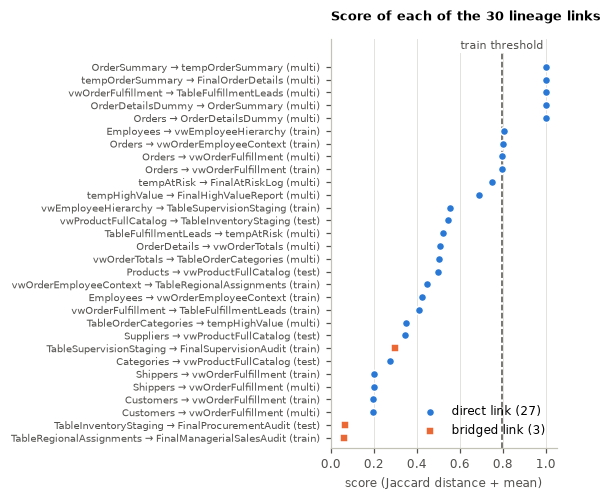

In [19]:
show = links.sort_values("score").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for kind, color, marker in [("direct", BLUE, "o"), ("bridged", ORANGE, "s")]:
    sub = show[show.link == kind]
    ax.scatter(sub.score, sub.index, color=color, s=28, marker=marker, edgecolors=SURFACE, linewidths=1,
               label=f"{kind} link ({len(sub)})", zorder=3)
ax.axvline(t_best, color=MUTED, linewidth=1, linestyle="--")
ax.text(t_best, len(show) + 0.2, "train threshold", fontsize=7, color=MUTED, ha="center", va="bottom",
        bbox={"facecolor": SURFACE, "edgecolor": "none", "pad": 1})
ax.set_ylim(-0.8, len(show) + 1.2)
ax.set_yticks(show.index, [f"{s} → {t} ({sp})" for s, t, sp in zip(show.source_name, show.target_name, show.split)],
              fontsize=6.5)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1.05)
ax.set_xlabel("score (Jaccard distance + mean)")
ax.legend(loc="lower right")
ax.set_title("Score of each of the 30 lineage links", pad=12)
fig.tight_layout()
fig.savefig(FIGURES / "exp_05_link_scores.png")
plt.show()

The lowest-scored links fall into three groups:

* **Bridged links** (orange) over temporary tables that were dropped before the export: the final table is a
  transformation of a table we never see, so little of it can be matched.
* **Join sources that gave a single column** (`Customers` / `Shippers -> vwOrderFulfillment`,
  `Categories -> vwProductFullCatalog`): `mean` dilutes one perfect column over the whole target. With `max`,
  `Shippers`, `Categories`, `Suppliers` and `Employees` move to rank 1 for their view (table above), but `max` is
  worse overall (section 3) because shared keys give it many false positives. Combining the two aggregations is
  an obvious next step.
* **Transformed columns** (aggregates, computed values), which neither names nor values can match, as predicted by
  the EDA (41 % of derived columns).

## 7. Comparison with the reference paper

The GNN of Dutkiewicz et al. is evaluated on **row-level** links (`rowDerivedFrom`) in a knowledge graph, on 9
tasks × 3 test scenarios, against 4,000 sampled negatives. We evaluate **table-level** links on the CSV exports,
against all other tables. The numbers therefore **cannot be compared directly**. To get as close as possible to
their Hits@10, we also rank each true link against random samples of negative pairs of its split.

In [20]:
# Table 3 of Dutkiewicz, Misiorek, Wrembel (arXiv:2605.16068): precision, recall, AUC (PR), Hits@10
paper_table = pd.DataFrame([
    ("Selection-projection", "baseline", 0.92, 0.95, 0.98, 0.62), ("Selection-projection", "RDDL", 0.95, 0.95, 0.98, 0.71),
    ("Selection-linear", "baseline", 0.94, 0.89, 0.98, 0.59), ("Selection-linear", "RDDL", 0.96, 0.96, 0.98, 0.74),
    ("Selection-nonlinear", "baseline", 0.91, 0.89, 0.97, 0.68), ("Selection-nonlinear", "RDDL", 0.95, 0.90, 0.98, 0.72),
    ("Join-projection", "baseline", 0.82, 0.84, 0.83, 0.45), ("Join-projection", "RDDL", 0.88, 0.91, 0.89, 0.68),
    ("Join-linear", "baseline", 0.79, 0.81, 0.78, 0.42), ("Join-linear", "RDDL", 0.83, 0.81, 0.84, 0.62),
    ("Join-nonlinear", "baseline", 0.85, 0.83, 0.83, 0.31), ("Join-nonlinear", "RDDL", 0.84, 0.85, 0.86, 0.57),
    ("Union-projection", "baseline", 0.86, 0.87, 0.88, 0.68), ("Union-projection", "RDDL", 0.94, 0.91, 0.91, 0.71),
    ("Union-linear", "baseline", 0.88, 0.89, 0.90, 0.62), ("Union-linear", "RDDL", 0.95, 0.93, 0.95, 0.67),
    ("Union-nonlinear", "baseline", 0.87, 0.91, 0.90, 0.67), ("Union-nonlinear", "RDDL", 0.93, 0.91, 0.91, 0.66),
], columns=["task", "ontology", "Precision", "Recall", "AUC (PR)", "Hits@10"])
paper = paper_table.groupby("ontology")[["Precision", "Recall", "AUC (PR)", "Hits@10"]].mean()
paper.index = [f"GNN, {o} ontology (mean of 9 tasks)" for o in paper.index]
join = paper_table[paper_table.task.str.startswith("Join")].groupby("ontology")[paper.columns].mean()
join.index = [f"GNN, {o} ontology (mean of 3 join tasks)" for o in join.index]
paper = pd.concat([paper, join])
held_best = best[best.split.isin(HELD_OUT)]
th = threshold_metrics(held_best, t_best)
ours = pd.DataFrame({
    "Precision": [th["Precision"], np.nan], "Recall": [th["Recall"], np.nan],
    "AUC (PR)": [ranking_metrics(held_best)["PR-AUC"], np.nan],
    "Hits@10": [hits_vs_sampled_negatives(held_best, negatives=50), hits_vs_sampled_negatives(held_best, negatives=100)],
}, index=["Valentine Jaccard + mean, held-out (Hits@10 vs 50 negatives)", "same, Hits@10 vs 100 negatives"])
pd.concat([paper, ours]).round(2)

,Precision,Recall,AUC (PR),Hits@10
"GNN, RDDL ontology (mean of 9 tasks)",0.91,0.90,0.92,0.68
"GNN, baseline ontology (mean of 9 tasks)",0.87,0.88,0.89,0.56
"GNN, RDDL ontology (mean of 3 join tasks)",0.85,0.86,0.86,0.62
"GNN, baseline ontology (mean of 3 join tasks)",0.82,0.83,0.81,0.39
"Valentine Jaccard + mean, held-out (Hits@10 vs 50 negatives)",0.27,0.32,0.21,0.74
"same, Hits@10 vs 100 negatives",NaN,NaN,NaN,0.53


*Paper means are computed from Table 3 of the paper (copied in the cell above); "AUC" there is the area under the
precision-recall curve. Our Hits@10 against 50 negatives is in the range of the paper's join tasks, but the
negative pool, granularity and data differ, so this is an orientation, not a head-to-head result.*

**What the comparison shows**

| | GNN on RDDL knowledge graph (paper) | Valentine (this project) |
|---|---|---|
| Training | ~5 M samples per graph, 3 epochs | **none** |
| Input | database converted to a KG with an ontology | **the tables themselves** (CSV / DataFrames) |
| Cost | KG construction + training | **< 4 min on one CPU core for all matchers and pairs** |
| New database | retrain or re-embed | **run directly** |
| Explanation of a prediction | a probability | **the matched columns** (`CompanyName ↔ CustomerName`) |
| Granularity | row level | table level (column level available) |
| Direction of the link | learned from paths | not given by the score (18/30 correct) |
| Transformed values | can be learned | not matched |
| Precision / recall | ~0.9 / ~0.9 (row level) | 0.27 / 0.32 (table level, exact edge); **1.0 same-chain precision** |
| Hits@10 | 0.57-0.74 (RDDL, by task) | 0.74 against 50 negatives, 0.53 against 100 |

**Pros of Valentine w.r.t. the baseline:** training-free, works directly on tables, cheap, transfers to any new
database immediately and every prediction comes with the column evidence that a data engineer can check. Its
highest-ranked pairs are always inside the right lineage chain. **Cons:** it does not decide the direction or the
exact edge in a chain, and it cannot see transformed columns. These are the targets of the second iteration.

## 8. Main outcomes

In [21]:
held_metrics = ranking_metrics(held_best)
outcomes = {
    "runtime, 6 configurations x 842 pairs": f"{timings.seconds.sum() / 60:.1f} min (no training)",
    "configuration chosen on train": f"{chosen[0]} + {chosen[1]}",
    "held-out PR-AUC (random)": f"{held_metrics['PR-AUC']:.2f} ({comparison.loc['random', 'PR-AUC']:.2f})",
    "held-out AUROC": f"{held_metrics['AUROC']:.2f}",
    "held-out Hits@1 / Hits@3 / MRR": f"{held_metrics['Hits@1']:.2f} / {held_metrics['Hits@3']:.2f} / {held_metrics['MRR']:.2f}",
    "held-out precision / recall at train threshold": f"{th['Precision']:.2f} / {th['Recall']:.2f}",
    "same-chain precision above threshold (all splits)": f"{best[best.score >= t_best].label.isin(related).mean():.2f}",
    "best schema-only PR-AUC (held-out)": f"{held.xs('COMA (schema)')['PR-AUC'].max():.2f}",
    "value containment baseline PR-AUC (held-out)": f"{comparison.loc['value containment', 'PR-AUC']:.2f}",
    "direction correct / tie / wrong": "/".join(str(int((direction.result == r).sum())) for r in ["correct", "tie", "wrong"]),
}
pd.Series(outcomes, name="value").to_frame()

,value
"runtime, 6 configurations x 842 pairs",1.8 min (no training)
configuration chosen on train,Jaccard distance + mean
held-out PR-AUC (random),0.21 (0.06)
held-out AUROC,0.86
held-out Hits@1 / Hits@3 / MRR,0.40 / 0.73 / 0.59
held-out precision / recall at train threshold,0.27 / 0.32
same-chain precision above threshold (all splits),1.00
best schema-only PR-AUC (held-out),0.18
value containment baseline PR-AUC (held-out),0.22
direction correct / tie / wrong,18/6/6


**Next steps (Milestone 5)**

1. Combine aggregations (`mean` for copies, `max` for join sources) and matchers (values + names).
2. Decide the direction with a second signal (object type, row counts, containment asymmetry).
3. Table names on/off experiment (`raw` / `base` / `neutral`, prepared in pre-processing).
4. Report results by lineage scenario type (selection, join, union), as in the paper.